In [2]:
import numpy as np
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier

In [3]:
seed = 26006
rng = np.random.default_rng(seed)

In [4]:
faces = fetch_olivetti_faces()
images = faces.images
data = faces.data # feature or X
target = faces.target # output 

In [5]:
# per person shuffle their 10 photos
# 6 to train, 2 to validate and 2 to test

train, validate, test = [], [], []

for person in range(40):
    index = rng.permutation(np.where(target == person)[0])
    train += list(index[:6])
    validate += list(index[6:8])
    test += list(index[8:])

train = np.array(train)
validate = np.array(validate)
test = np.array(test)
# or this way -> 
# train, validate, test = map(np.array, (train, validate, test))



In [6]:
data_train, target_train = data[train], target[train]
data_validate, target_validate = data[validate], target[validate]
data_test, target_test = data[test], target[test]

In [7]:
# question 2 

# multiclass boosting from scratch 


(a) Before using the face data, create a three class example with at most 10 samples. Log one complete SAMME
round: initial sample weights, weak learner predictions, weighted error, αt, and updated normalised weights.
Your implementation on the face data must use the same update rule.

In [8]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

In [9]:
# create a 3 class sample with at most 10 samples

x_toy = np.array([[1,1], [2,2], [3,3], [9,9], [5,5]])
y_toy = np.array([0, 0, 1, 1, 2])
K = 3
N = len(x_toy)


In [10]:
# step 1: initial sample weights (everyone is equal at the start)

w = np.ones(N)
w = w/N
print("initial weights =", w)

initial weights = [0.2 0.2 0.2 0.2 0.2]


In [11]:
# step 2: train a week learner and get predictions 
# depth 1 tree is a standard week learner 

learner = DecisionTreeClassifier(max_depth=1, random_state=42)
learner.fit(x_toy, y_toy, sample_weight=w)
preds = learner.predict(x_toy)
print("Predictions:", preds)
print("True Labels:", y_toy)

Predictions: [0 0 1 1 1]
True Labels: [0 0 1 1 2]


In [12]:
# step 3: calculate the weighted error (epsilon_t)
# sum of the weights of the incorrect predictiosn 

incorrect = (preds != y_toy)
print(incorrect)
print(w[incorrect])
s = np.sum(w[incorrect])
print(s)
print(np.sum(w))
err = np.sum(w[incorrect]) / np.sum(w)
print("weighted_error (epsilon_t): %.4f" %err)

[False False False False  True]
[0.2]
0.2
1.0
weighted_error (epsilon_t): 0.2000


In [13]:
# random guessing error for k classes is (k-1)/k. 
# for 3 classes it is 0.66
# if err >= 0.66, this learner is useless 
# in a full loop, we'd stop or discard it 

# step 4: calculate the learner weight (alpha_t) using the provided formula
alpha = np.log((1 - err) / err) + np.log(K - 1)
print("learner weight (alpha_t): %.4f" %alpha)

learner weight (alpha_t): 2.0794


In [14]:
# step 5: update and normalize sample weights 
# we multiply the weight by e^alpha for incorrect predictions to make them heavier 
w = w * np.exp(alpha * incorrect)
w = w / np.sum(w) # normalization so weights sum to 1 
print("updated normalized weights: ", w)

updated normalized weights:  [0.08333333 0.08333333 0.08333333 0.08333333 0.66666667]


(b) On Olivetti Faces, use weak learner depths 1, 2, 3, 4 and 10, 25, 50, 100 rounds. Select depth and rounds using
clean validation accuracy only. For the selected model, plot weighted training error, learner weight, maximum
sample weight and the total weight carried by the 10 heaviest training images over rounds.

In [15]:
import matplotlib.pyplot as plt 
from sklearn.metrics import accuracy_score

In [16]:
def train_samme(x_train, y_train, depth, num_rounds):
    N = len(x_train)
    K = 40 
    w = np.ones(N) / N

    models = []
    alphas = []

    track_errors = []
    track_alphas = []
    track_max_w = []
    track_top10_w = []

    for t in range(num_rounds):
        # train week learner 
        tree = DecisionTreeClassifier(max_depth=depth, random_state=seed)
        tree.fit(x_train, y_train, sample_weight=w)
        preds = tree.predict(x_train)

        # calculate the weighted error 
        incorrect = (preds != y_train)
        err = np.sum(w[incorrect]) / np.sum(w)

        # stop if the learner is wrose than random guessing 
        if err >= (K - 1) / K:
            break 

        # calculate alpha (learner weight)
        alpha = np.log((1 - err) / err) + np.log(K - 1)

        # save metrics for plotting 
        track_errors.append(err)
        track_alphas.append(alpha)
        track_max_w.append(np.max(w))

        # sort the weights in descending order and sum the top 10 
        track_top10_w.append(np.sum(np.sort(w)[::-1][:10]))

        # update and normalize weights
        w = w * np.exp(alpha * incorrect)
        w = w / np.sum(w)

        # save the tree and its weight
        models.append(tree)
        alphas.append(alpha)
    
    return models, alphas, track_errors, track_alphas, track_max_w, track_top10_w

In [17]:
def predict_samme(x, models, alphas):
    K = 40
    # create an empty scoreboard for each class 
    scores = np.zeros((len(x), K))

    # each tree casts a weighted vote 
    for tree, alpha in zip(models, alphas):
        preds = tree.predict(x)
        for i, p in enumerate(preds):
            scores[i, p] += alpha

    # the class with the highest score wins
    return np.argmax(scores, axis=1)

Depth: 1 Rounds: 10 val accuracy: 0.0375
Depth: 1 Rounds: 25 val accuracy: 0.0500
Depth: 1 Rounds: 50 val accuracy: 0.1375
Depth: 1 Rounds: 100 val accuracy: 0.1500
Depth: 2 Rounds: 10 val accuracy: 0.0625
Depth: 2 Rounds: 25 val accuracy: 0.1000
Depth: 2 Rounds: 50 val accuracy: 0.1000
Depth: 2 Rounds: 100 val accuracy: 0.1875
Depth: 3 Rounds: 10 val accuracy: 0.0625
Depth: 3 Rounds: 25 val accuracy: 0.1500
Depth: 3 Rounds: 50 val accuracy: 0.2000
Depth: 3 Rounds: 100 val accuracy: 0.3125
Depth: 4 Rounds: 10 val accuracy: 0.2250
Depth: 4 Rounds: 25 val accuracy: 0.2500
Depth: 4 Rounds: 50 val accuracy: 0.1875
Depth: 4 Rounds: 100 val accuracy: 0.4750
Best Model: Depth 4, Rounds 100 Validation Accuracy: 0.4750


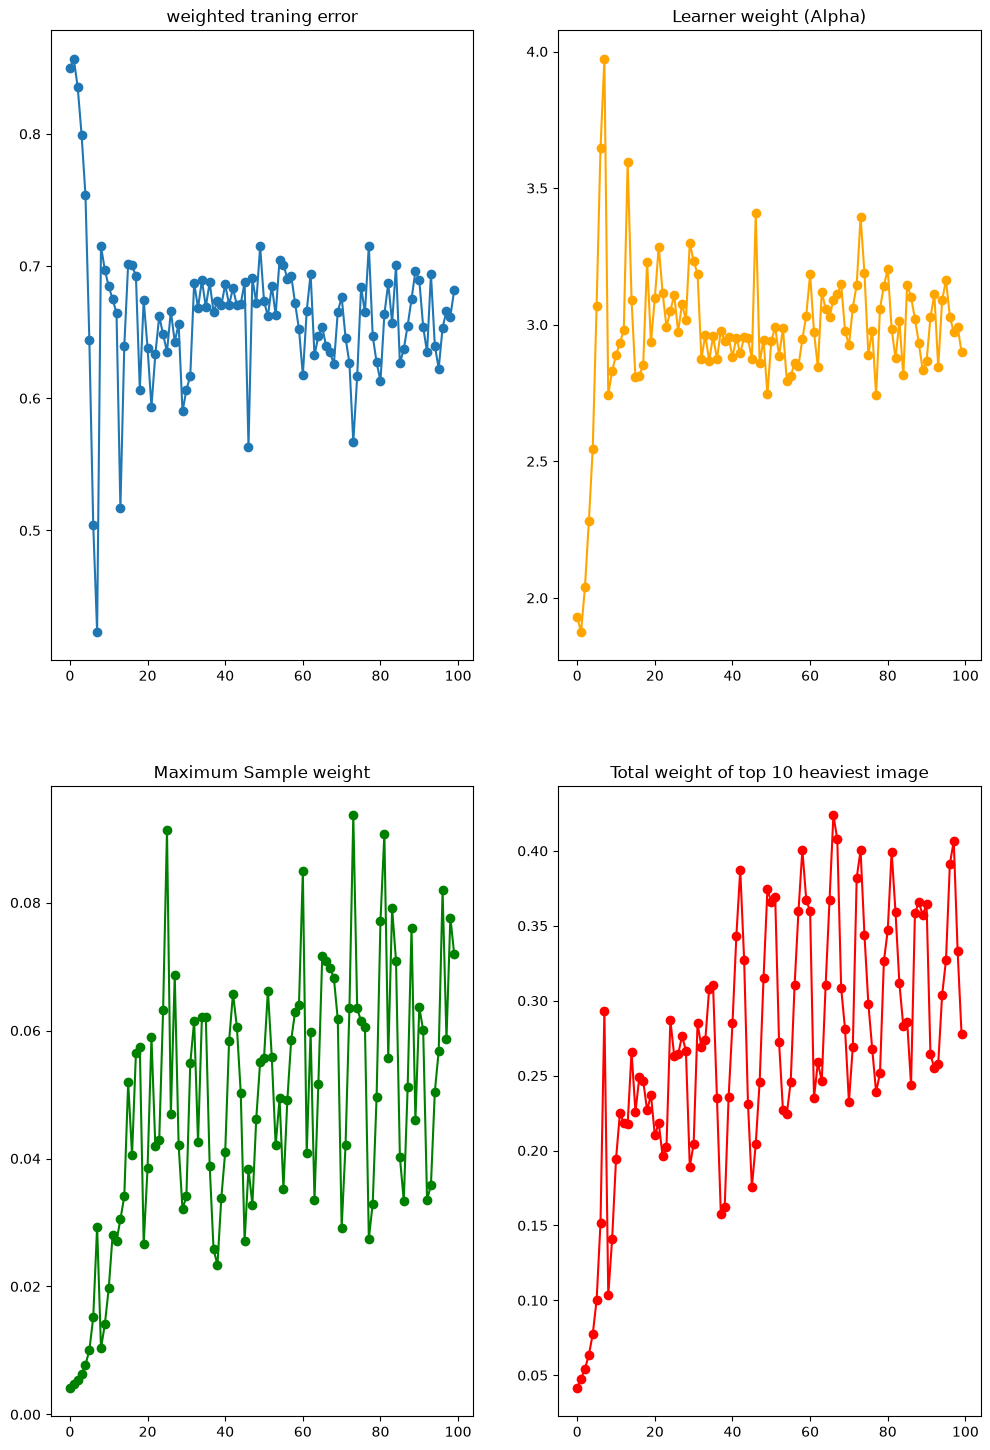

In [18]:
# plotting 

depths = [1, 2, 3, 4]
rounds_list = [10, 25, 50, 100]

best_acc = 0
best_params = None
best_metrics = None

# test all combinations 
for d in depths:
    for r in rounds_list:
        # train on the training data 
        models, alphas, t_err, t_alpha, t_max_w, t_top10 = train_samme(data_train, target_train, d, r)

        # validate on the validation data 
        val_preds = predict_samme(data_validate, models, alphas)
        acc = accuracy_score(target_validate, val_preds)

        print("Depth:", d, "Rounds:", r, "val accuracy: %.4f" %acc)

        # keep track of the best one 
        if acc > best_acc:
            best_acc = acc
            best_params = (d, r)
            best_metrics = (t_err, t_alpha, t_max_w, t_top10)

print(f"Best Model: Depth {best_params[0]}, Rounds {best_params[1]} Validation Accuracy: {best_acc:.4f}")

# plotting the 4 required metrixs for the best model
t_err, t_alpha, t_max_w, t_top10 = best_metrics
rounds_range = range(len(t_err))

plt.figure(figsize=(12, 18))

plt.subplot(2, 2, 1)
plt.plot(rounds_range, t_err, marker="o")
plt.title("weighted traning error")

plt.subplot(2, 2, 2)
plt.plot(rounds_range, t_alpha, marker="o", color="orange")
plt.title("Learner weight (Alpha)")

plt.subplot(2, 2, 3)
plt.plot(rounds_range, t_max_w, marker="o", color="green")
plt.title("Maximum Sample weight")

plt.subplot(2, 2, 4)
plt.plot(rounds_range, t_top10, marker="o", color="red")
plt.title("Total weight of top 10 heaviest image")

plt.show()

(C) Compare boosting and bagging using 25, 50 and 100 learners. Report train, validation and clean test accuracy
and training time. Also inspect one training face that receives a very large boosting weight and use its prediction
history to explain why boosting repeatedly returns attention to that sample.

In [19]:
import time 
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt 

In [20]:
best_depth = 4 
n_learners = [25, 50, 100]

print("Bagging vs Boosting Comparison")

for n in n_learners:
    # 1. Bagging 
    start_time = time.time()
    bagging = BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=best_depth, random_state=26006), n_estimators=n, random_state=26006)
    bagging.fit(data_train, target_train)
    bag_time = time.time() - start_time

    bag_train_acc = accuracy_score(target_train, bagging.predict(data_train))
    bag_val_acc = accuracy_score(target_validate, bagging.predict(data_validate))
    bag_test_acc = accuracy_score(target_test, bagging.predict(data_test))

    # 2. Boosting

    start_time = time.time()
    models, alphas, _, _, _, _ = train_samme(data_train, target_train, best_depth, n)
    boost_time = time.time() - start_time

    boost_train_acc = accuracy_score(target_train, predict_samme(data_train, models, alphas))
    boost_val_acc = accuracy_score(target_validate, predict_samme(data_validate, models, alphas))
    boost_test_acc = accuracy_score(target_test, predict_samme(data_test, models, alphas))

    print(f"Learners: {n}")
    print(f"Bagging -> Time: {bag_time: .2f}, Train: {bag_train_acc:.2f}, val: {bag_val_acc:.2f}, time: {bag_test_acc:.2f}")
    print(f"Boosting -> Time: {boost_time:.2f}, Train: {boost_train_acc:.2f}, val : {boost_val_acc:.2f}, test: {boost_test_acc:.2f}")


Bagging vs Boosting Comparison
Learners: 25
Bagging -> Time:  8.91, Train: 0.68, val: 0.51, time: 0.51
Boosting -> Time: 13.41, Train: 0.53, val : 0.25, test: 0.28
Learners: 50
Bagging -> Time:  12.65, Train: 0.81, val: 0.60, time: 0.65
Boosting -> Time: 23.56, Train: 0.49, val : 0.19, test: 0.14
Learners: 100
Bagging -> Time:  40.17, Train: 0.88, val: 0.62, time: 0.69
Boosting -> Time: 39.65, Train: 1.00, val : 0.47, test: 0.41


In [22]:
# inspecting the heaviest face 

models, alphas, _, _, _, _ = train_samme(data_train, target_train, best_depth, 100)

w = np.ones(len(data_train)) / len(data_train)
for tree, alpha in zip(models, alphas):
    preds = tree.predict(data_train)
    incorrect = (preds != target_train)
    w = w * np.exp(alpha * incorrect)
    w = w / np.sum(w)

In [23]:
# find the index of the highest weight

hardest_idx = np.argmax(w)
true_label  = target_train[hardest_idx]

In [24]:
# check what every single tree predicts for this specific face 

history = []
for tree in models:
    pred = tree.predict([data_train[hardest_idx]])[0]
    history.append(pred)

In [25]:
errors = sum(1 for p in history if p!= true_label)

In [26]:
print("Heaviest Face Analysis")
print(f"Index: {hardest_idx}, true label: {true_label}")
print(f"this face was misclassified {errors} times out of 100 rounds")

Heaviest Face Analysis
Index: 236, true label: 39
this face was misclassified 88 times out of 100 rounds


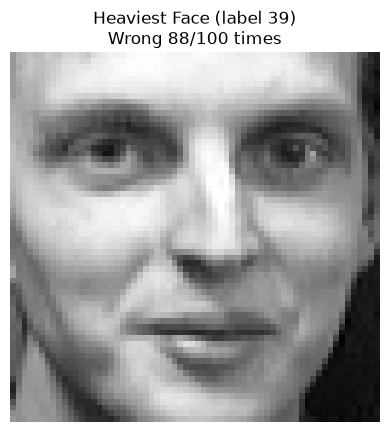

In [27]:
plt.imshow(data_train[hardest_idx].reshape(64, 64), cmap="gray")
plt.title(f"Heaviest Face (label {true_label})\nWrong {errors}/100 times")
plt.axis("off")
plt.show()

we can see exactly how many times out of 100 the weak learners failed on that specific image. Boosting returns attention to this sample repeatedly because it represents an outlier or a highly confusing case (e.g., shadows, unusual expression, or looking similar to another class). Because early learners get it wrong, its weight grows exponentially. Subsequent learners are forced to try to classify it correctly to minimize their weighted error, but due to their restricted depth, they often fail, causing the sample's weight to balloon further

(d) Freeze the selected boosting model. Evaluate the single tree baseline, final bagged model and boosting model on
the clean and masked test sets. Report accuracy and mean winning vote or probability for each. Find one face
for which bagging and boosting respond differently to the missing region and explain the difference using tree
disagreement and boosting sample weighting.

In [28]:
# 1. Create the masked test set (black out the bottom half of the 64x64 images)
data_test_masked = data_test.copy()
for i in range(len(data_test_masked)):
    img = data_test_masked[i].reshape(64, 64)
    img[32:, :] = 0  # Set bottom half pixels to 0
    data_test_masked[i] = img.flatten()

# Re-initialize models using the best parameters 
best_depth = 4
n_learners = 100

# Train Single Tree Baseline
single_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=26006)
single_tree.fit(data_train, target_train)

# Train Bagged Model
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=best_depth, random_state=26006),
    n_estimators=n_learners,
    random_state=26006
)
bagging.fit(data_train, target_train)

def predict_and_confidence_samme(X, models, alphas):
    K = 40
    scores = np.zeros((len(X), K))
    for tree, alpha in zip(models, alphas):
        preds = tree.predict(X)
        for i, p in enumerate(preds):
            scores[i, p] += alpha
            
    q = scores / np.sum(alphas)
    winning_votes = np.max(q, axis=1)
    predictions = np.argmax(q, axis=1)
    return predictions, winning_votes

def evaluate_model(name, model_type, X_clean, X_masked, y):
    print(f"\n--- {name} ---")
    if model_type == "samme":
        clean_preds, clean_conf = predict_and_confidence_samme(X_clean, models, alphas)
        mask_preds, mask_conf = predict_and_confidence_samme(X_masked, models, alphas)
    else:
        
        clean_preds = model_type.predict(X_clean)
        clean_conf = np.max(model_type.predict_proba(X_clean), axis=1)
        mask_preds = model_type.predict(X_masked)
        mask_conf = np.max(model_type.predict_proba(X_masked), axis=1)
        
    print(f"Clean  -> Acc: {accuracy_score(y, clean_preds):.4f} | Mean Confidence: {np.mean(clean_conf):.4f}")
    print(f"Masked -> Acc: {accuracy_score(y, mask_preds):.4f} | Mean Confidence: {np.mean(mask_conf):.4f}")
    
    return mask_preds


In [29]:
# 2. Evaluate all three models
single_mask_preds = evaluate_model("Single Tree", single_tree, data_test, data_test_masked, target_test)
bag_mask_preds = evaluate_model("Bagging", bagging, data_test, data_test_masked, target_test)
boost_mask_preds = evaluate_model("Boosting", "samme", data_test, data_test_masked, target_test)


--- Single Tree ---
Clean  -> Acc: 0.1125 | Mean Confidence: 0.1250
Masked -> Acc: 0.0500 | Mean Confidence: 1.0000

--- Bagging ---
Clean  -> Acc: 0.6875 | Mean Confidence: 0.1059
Masked -> Acc: 0.1000 | Mean Confidence: 0.1520

--- Boosting ---
Clean  -> Acc: 0.4125 | Mean Confidence: 0.1198
Masked -> Acc: 0.0875 | Mean Confidence: 0.1139



--- Disagreement Analysis for Test Index 4 ---
True Label: 2 | Bagging Guessed: 26 | Boosting Guessed: 36


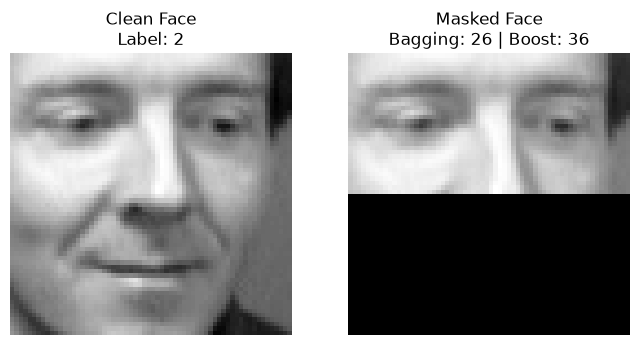

In [30]:

# 3. Find a face where Bagging and Boosting disagree on the masked set
disagreements = np.where(bag_mask_preds != boost_mask_preds)[0]

if len(disagreements) > 0:
    idx = disagreements[0]
    true_label = target_test[idx]
    bag_pred = bag_mask_preds[idx]
    boost_pred = boost_mask_preds[idx]
    
    print(f"\n--- Disagreement Analysis for Test Index {idx} ---")
    print(f"True Label: {true_label} | Bagging Guessed: {bag_pred} | Boosting Guessed: {boost_pred}")
    
    # Plot the clean and masked face
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(data_test[idx].reshape(64, 64), cmap='gray')
    axes[0].set_title(f"Clean Face\nLabel: {true_label}")
    axes[0].axis('off')
    
    axes[1].imshow(data_test_masked[idx].reshape(64, 64), cmap='gray')
    axes[1].set_title(f"Masked Face\nBagging: {bag_pred} | Boost: {boost_pred}")
    axes[1].axis('off')
    plt.show()
else:
    print("\nNo disagreements found between Bagging and Boosting on the masked test set.")